In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
# Setup and imports for archetypal analysis using the new package
import pandas as pd
import numpy as np
from tqdm import tqdm
import time
import matplotlib.pyplot as plt
import os
import json
import sys

# Import the new archetypal_analysis package
sys.path.append('./archetypal_analysis')

from archetypal_analysis.data.loaders import CompendiumDataLoader, HadzaDataLoader, ArchetypalResultLoader
from archetypal_analysis.data.normalizers import DataNormalizer
from archetypal_analysis.data.formatters import DataTransformer
from archetypal_analysis.data.quality_control import QualityController
from archetypal_analysis.analysis.archetypal import ArchetypalAnalysis, ArchetypalAnalysisResult
from archetypal_analysis.analysis.metrics import AnalysisMetrics
from archetypal_analysis.visualization.simplex import SimplexPlotter
from archetypal_analysis.visualization.pcoa import PCoAVisualizer
from archetypal_analysis.visualization.composition import CompositionAnalyzer

from archetypal_analysis.visualization.stacked_bar import StackedBarPlotter
from archetypal_analysis.utils.metadata import extract_metadata
from archetypal_analysis.utils.file_io import ResultsManager
from archetypal_analysis.config import AnalysisConfig

# For compatibility with original archetypes package visualization
from archetypes.visualization import stacked_bar, simplex
from archetypes.datasets import sort_by_archetype_similarity, permute_dataset

print("Archetypal analysis package loaded successfully!")

Couldn't import dot_parser, loading of dot files will not be possible.
Archetypal analysis package loaded successfully!


## Performing AA

In [3]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = r"datasets\compendium\normalized\compendium_Norm_QC-sample_type400.csv"

loader = CompendiumDataLoader()
otu = loader.load_otu_table(otuFile)

In [9]:
FRAC = 1.0
LOG_TRANSFORM = True
N_ARCHETYPES = 5
aa = ArchetypalAnalysis(
    n_archetypes=N_ARCHETYPES,
    method="pgd",
    max_iter=100,
)

result = aa.fit_transform(otu, 
                          apply_log_transform=LOG_TRANSFORM, 
                          sample_fraction=FRAC)


Starting archetypal analysis with 5 archetypes...
Input data shape: (333, 574)
Processed data shape: (333, 574)
Fitting archetypal analysis model...
Model fitting completed.
Analysis completed. Final loss: 508658.840836


In [10]:
aa.save_results(result, outDir, frac=FRAC)

Saved archetypal analysis results to results\otu_AA_K5_1.0_None_jensenshannon.json


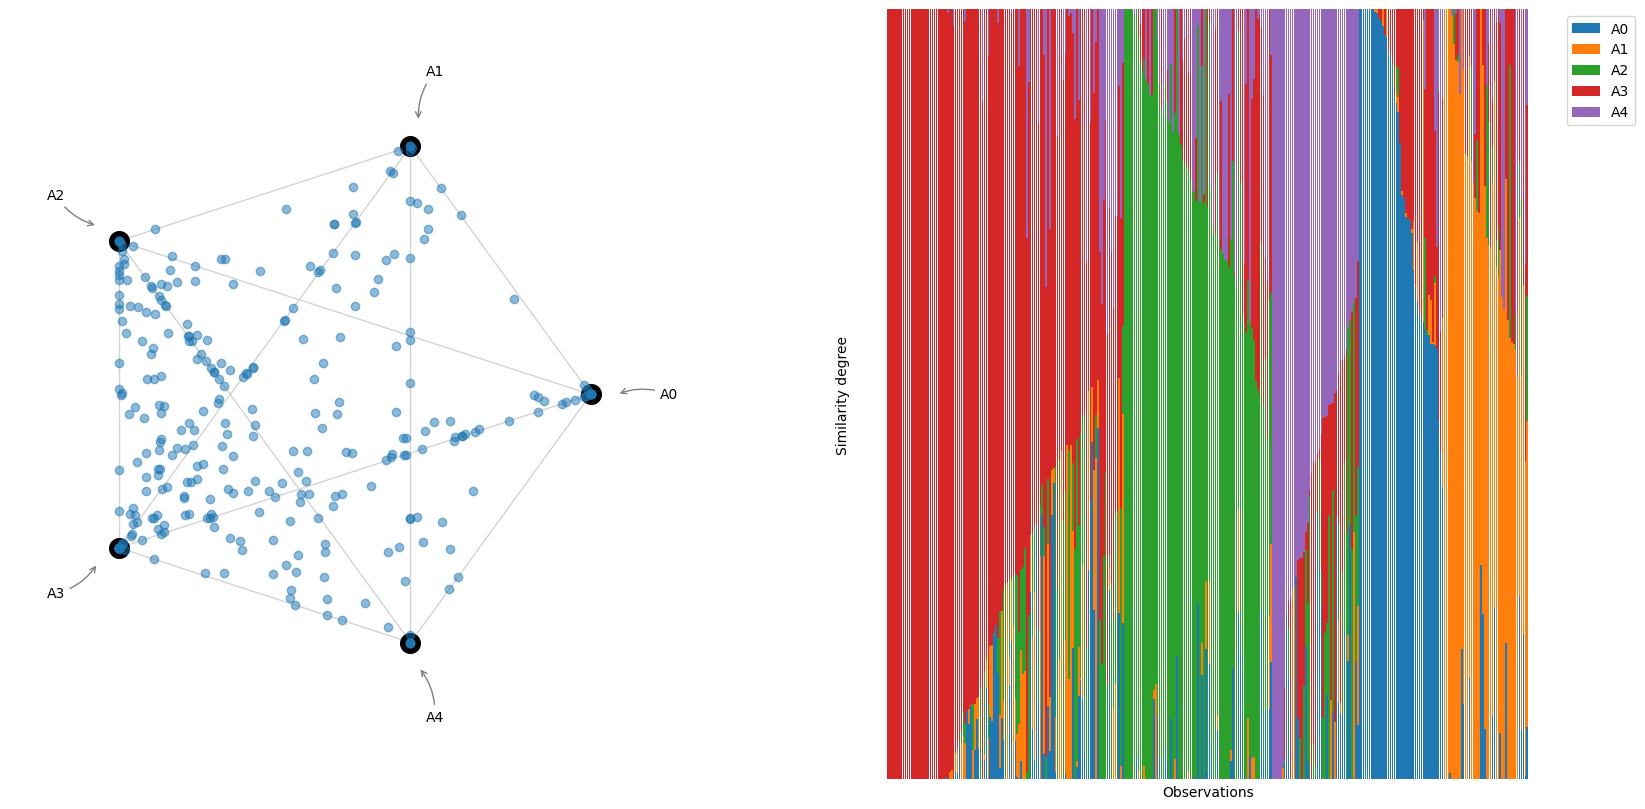

In [12]:
otu_np = otu.to_numpy()

# Get similarity degree and archetypes from the result object
similarity_degree = result.similarity_degree.to_numpy()
archetypes = result.archetypes

data_sorted, info = sort_by_archetype_similarity(otu_np, [similarity_degree], archetypes)
similarity_degree_permuted, _ = permute_dataset(similarity_degree, info["perms"])

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
simplex(similarity_degree, alpha=0.5, ax=ax[0], show_vertices=True)
stacked_bar(similarity_degree_permuted, ax=ax[1])

plt.show()


## Standard Analysis

### Loading Results

In [46]:
dataDir = "datasets/tsv"
filepath = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter_QC-Region3k_AdultsOnly\otu_AA_K6_1.0_None_jensenshannon.json" 

loader = ArchetypalResultLoader()
otu_aa, aa_labels, aa_archetypes, info = loader.load_parsed_result(filepath)

simplex_plotter = SimplexPlotter()


In [58]:
data_loader = CompendiumDataLoader()
projects_file = r"datasets/compendium/projects.csv"
tags_file = r"datasets/compendium/tags.tsv"
meta_file = r"datasets/compendium/sample_metadata.tsv"

_, projects, tags, meta = data_loader.load_all(otu_file=None, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)

### Plotting Plain Simplex Graph

C:\Users\rayve\AppData\Local\Temp\ipykernel_41540\1701354116.py:7: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



<Axes: >

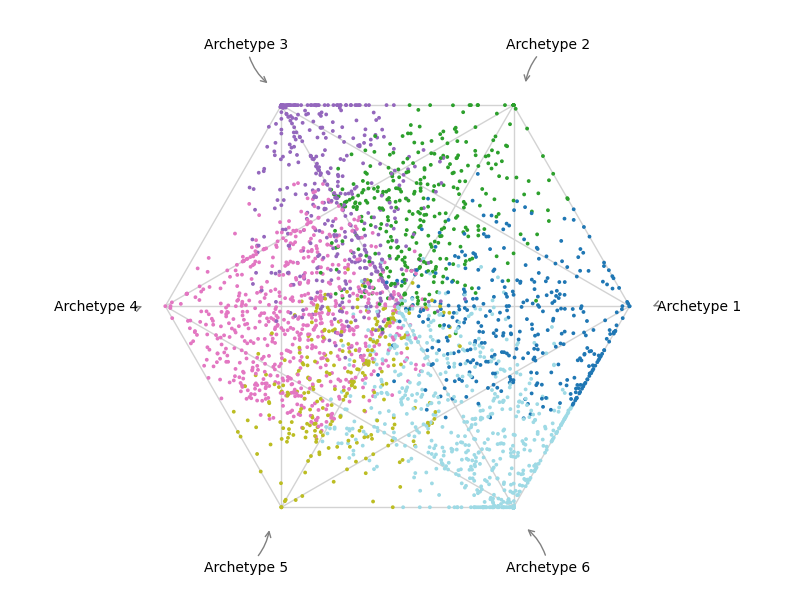

In [48]:
n_archs = len(aa_archetypes)
# Normalize the aa_labels
otu_aa_swapped = otu_aa.copy()

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa.to_numpy(), alpha=1, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa.columns)


### Reordering (optional)
Sometimes the graph is quite messy, with prominent lines going through the middle. <br>
You may find it helpful to reorder the archetypes. This can be done by changing the array below in order
Caution: This depends on how many archetypes there are. You may have to change the ordering for each new result loaded. 

In [59]:
# otu_aa_swapped = otu_aa[[ "Archetype 1","Archetype 2", "Archetype 7", "Archetype 3","Archetype 6", "Archetype 4", "Archetype 5"]]
otu_aa_swapped = otu_aa
# otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 3", "Archetype 5", "Archetype 6", "Archetype 2" , "Archetype 4"]]

### Plotting by Filter with Color
Below is the usage of the plot_simplex() utility for plotting by location. Here, `filter_cols` contains the columns of the sample dataset to filter by. <br>
`legend_type` parameter sets whether the values are "discrete" or "continuous"

In [64]:
metadata["condition"].value_counts()

condition
healthy                      1203
allergy + healthy             288
colorectal cancer             150
HIV                           138
CDI                           134
                             ... 
HIV + healthy                   1
Anal Precancerous Lesions       1
post-COVID                      1
atopic asthma + healthy         1
rheumatoid arthritis            1
Name: count, Length: 76, dtype: int64

Project columns: ['condition']
Sample columns: []
Tag columns: []


<Axes: >

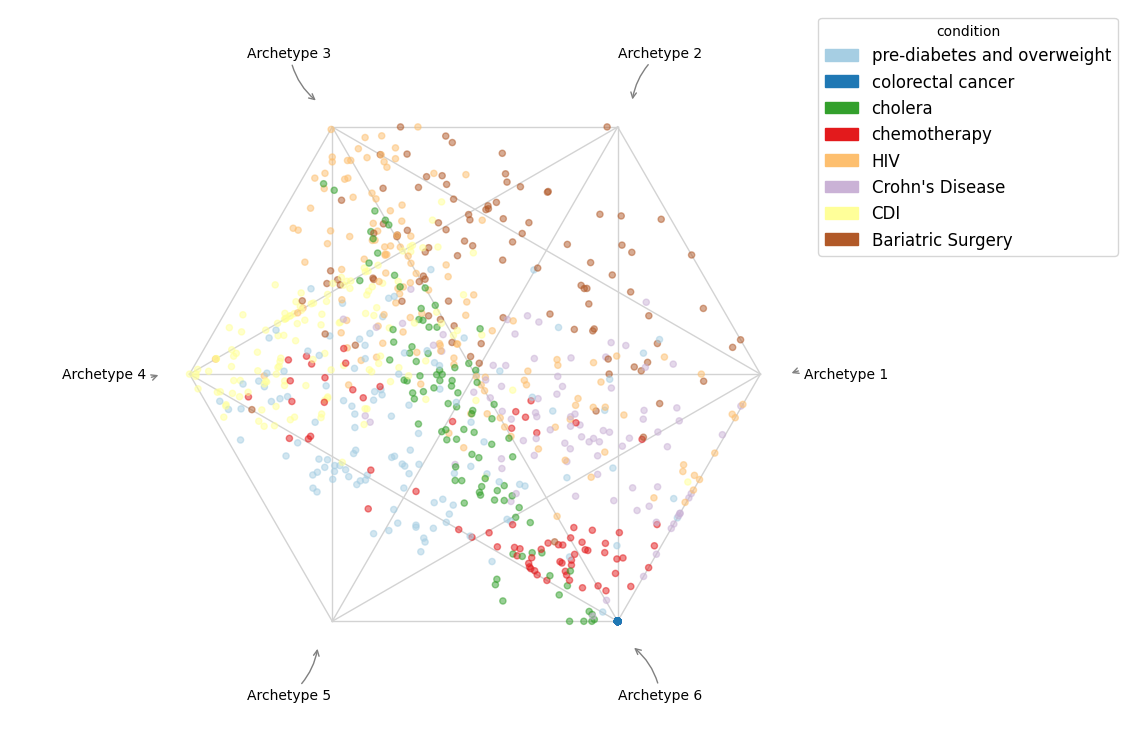

In [67]:
filter_cols = ["condition"]
metadata = extract_metadata(otu_aa_swapped.index, tags, meta, projects, filter_cols, verbose=True)

conditions = ["colorectal cancer", "HIV", "CDI", "pre-diabetes and overweight", "Bariatric Surgery", "cholera", "Crohn's Disease", "chemotherapy"]
metadata = metadata[metadata["condition"].isin(conditions)]

simplex_plotter.plot_simplex(
    otu_aa=otu_aa_swapped, 
    metadata=metadata, 
    filter_cols=filter_cols, 
    cmap_name="Paired", 
    legend_type="discrete", 
    remove_nan=True,
    alpha = 0.5,
    s=20,
    remove_values={"region": "unknown"},
    figsize=(12, 10)
)

Similarly, for age. This time, the `legend_type` is "continuous"

In [ ]:
filter_cols = ["age_months"]
metadata = extract_metadata(otu_aa_swapped.index, tags, meta, projects, filter_cols, verbose=True)
simplex_plotter.plot_simplex(
    otu_aa=otu_aa_swapped,
    metadata=metadata,
    filter_cols=filter_cols,
    cmap_name="viridis",
    legend_type="continuous",
    remove_nan=True,
    alpha = 0.5,
    s=10,
    remove_values={"age_months": "unknown"},
    figsize=(12, 10)
)


### Group Plotting

100%|██████████| 6/6 [00:00<00:00, 15.91it/s]


(<Figure size 1600x1920 with 6 Axes>,
 array([[<Axes: title={'center': 'K = 4'}>,
         <Axes: title={'center': 'K = 5'}>],
        [<Axes: title={'center': 'K = 6'}>,
         <Axes: title={'center': 'K = 7'}>],
        [<Axes: title={'center': 'K = 8'}>,
         <Axes: title={'center': 'K = 12'}>]], dtype=object))

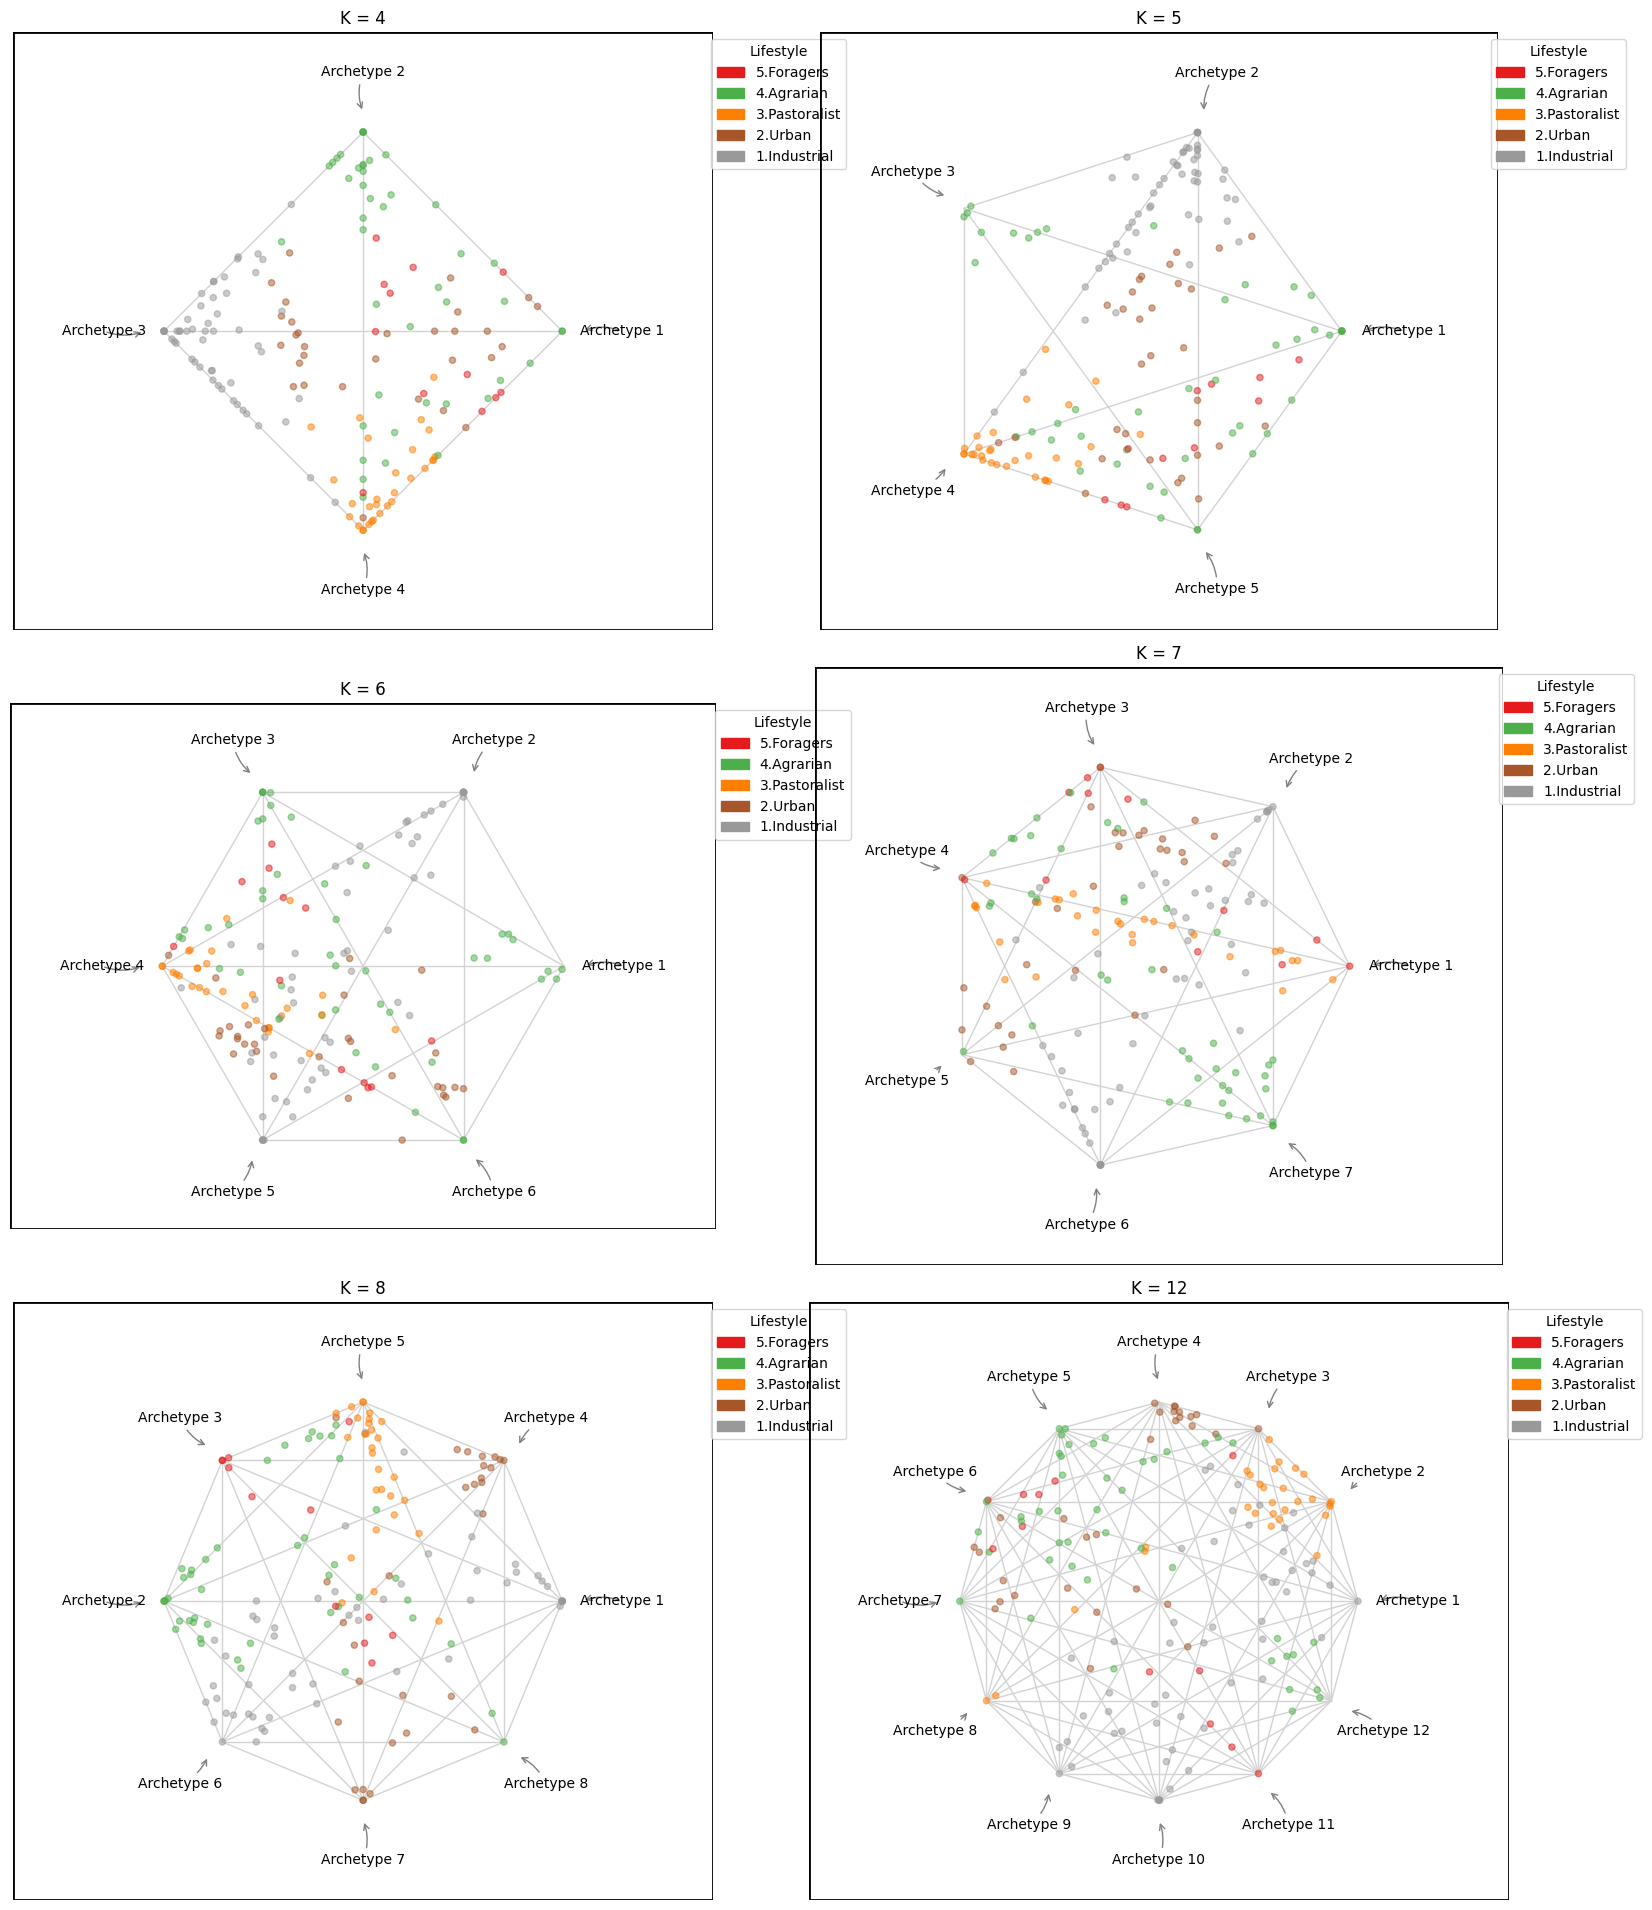

In [71]:
data_loader = CompendiumDataLoader()
projects_file = r"datasets/compendium/projects.csv"
tags_file = r"datasets/compendium/tags.tsv"
meta_file = r"datasets\tsv\dog_sam.tsv"

_, projects, tags, meta = data_loader.load_all(otu_file=None, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)

dir = r"results\Dog\norm_lifestyle200"
filter_cols = ["Lifestyle"]
legend_type = "discrete" # "continuous" #  

remove_values = {} #{"sample_type": "unknown"}

numKs =  [4,5,6,7,8,12] #[3,6,7,8,9,11] # 
swapped_cols = {
    # Region7k 
    # 8: ["Archetype 1", "Archetype 4", "Archetype 8", "Archetype 7", "Archetype 6", "Archetype 2", "Archetype 5", "Archetype 3"],
    # Region30k
    # 7: [ "Archetype 1","Archetype 2", "Archetype 7", "Archetype 3","Archetype 6", "Archetype 4", "Archetype 5"]
    # Region3k_AdultsOnly
    # 10: ["Archetype 1", "Archetype 2", "Archetype 3", "Archetype 9", "Archetype 4", "Archetype 8", "Archetype 5", "Archetype 6", "Archetype 7",  "Archetype 10"],
    # Hadza Region10k
    # 7: ["Archetype 1", "Archetype 3", "Archetype 6", "Archetype 2",  "Archetype 4", "Archetype 7", "Archetype 5"],
    # Hadza Age1k
    8: ["Archetype 1", "Archetype 4", "Archetype 5","Archetype 3", "Archetype 2",  "Archetype 6", "Archetype 7", "Archetype 8"],
}

simplex_plotter.plot_group_simplex(
    directory=dir, 
    k_values=numKs,
    filter_cols=filter_cols, 
    swapped_cols=swapped_cols, 
    legend_type=legend_type, 
    projects=projects, meta=meta, tags=tags,
    remove_values=remove_values, 
    cmap_name="Set1", 
    alpha = 0.5,
    s=20,
)

## Display Archetype Composition

In [91]:
otu_file = r"datasets\tsv\normalized\hadza_otu_normalized_age.csv"
loader = HadzaDataLoader()
otu = loader.load_otu_table(filename=otu_file)

filepath = r"results\Hadza\norm_qc_age1k\otu_AA_K8_1.0_None_jensenshannon.json"
loader = ArchetypalResultLoader()
otu_aa, aa_labels, aa_archetypes, info = loader.load_parsed_result(filepath)


In [92]:
composition_analyzer = CompositionAnalyzer()
NUM_TAXA = 3
top_taxa_archs = composition_analyzer.analyze_top_taxa(
    archetypes=aa_archetypes,
    feature_names=otu.columns,
    num_taxa=NUM_TAXA,
)


### Separate Bar Charts

c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\composition.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_ylim(0, max_val)
c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\composition.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_ylim(0, max_val)
c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\composition.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_ylim(0, max_val)
c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analys

(<Figure size 1500x800 with 8 Axes>,
 array([<Axes: title={'center': 'Archetype 1'}>,
        <Axes: title={'center': 'Archetype 2'}>,
        <Axes: title={'center': 'Archetype 3'}>,
        <Axes: title={'center': 'Archetype 4'}>,
        <Axes: title={'center': 'Archetype 5'}>,
        <Axes: title={'center': 'Archetype 6'}>,
        <Axes: title={'center': 'Archetype 7'}>, <Axes: >], dtype=object))

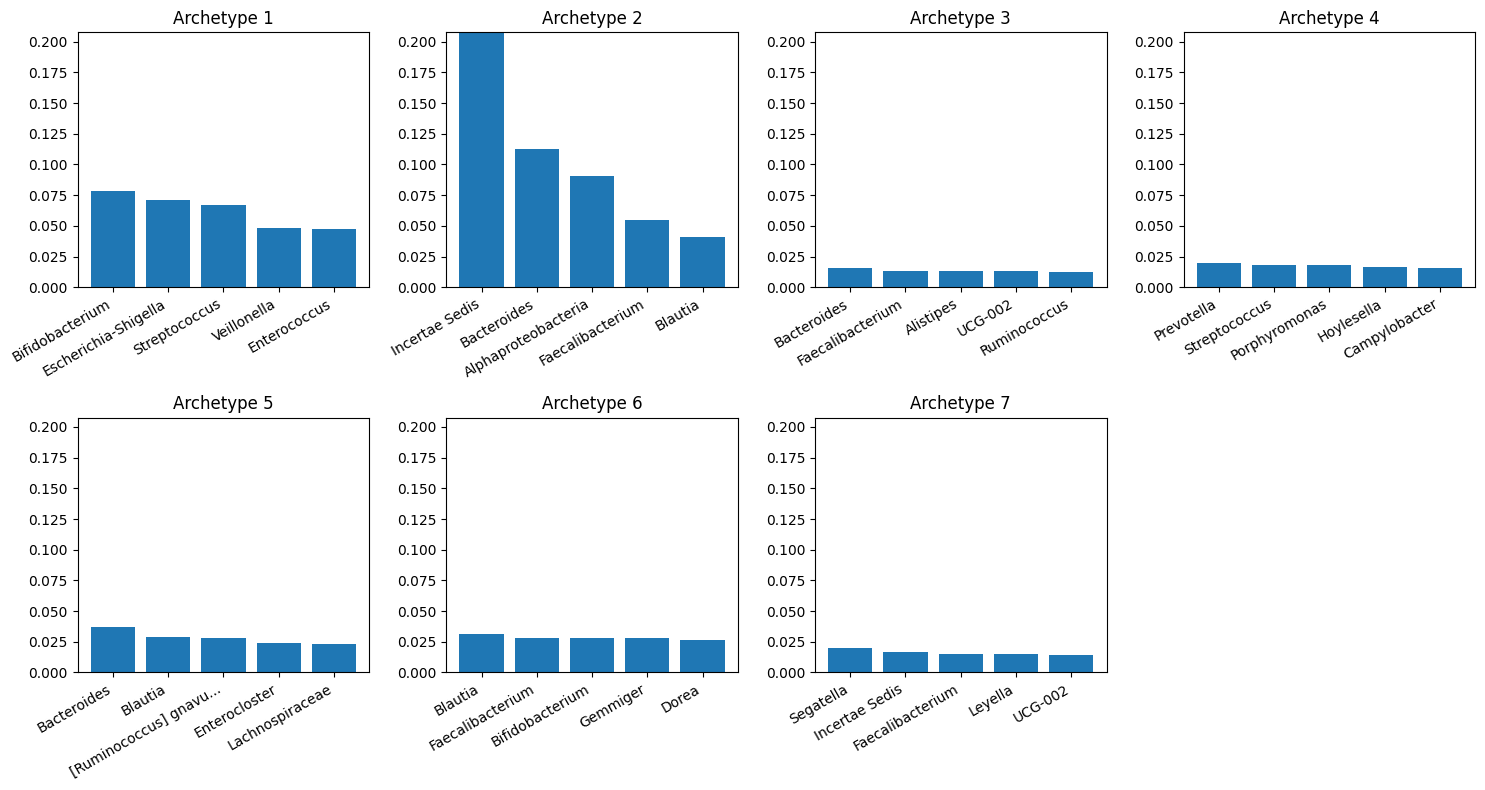

In [114]:
composition_analyzer.plot_separate_bar_charts(top_taxa_archetypes= top_taxa_archs)

### Stacked Bar Plot

(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Stacked Bar Chart: Top Taxa Contribution by Archetype'}, xlabel='Archetypes', ylabel='Percentage Contribution (%)'>)

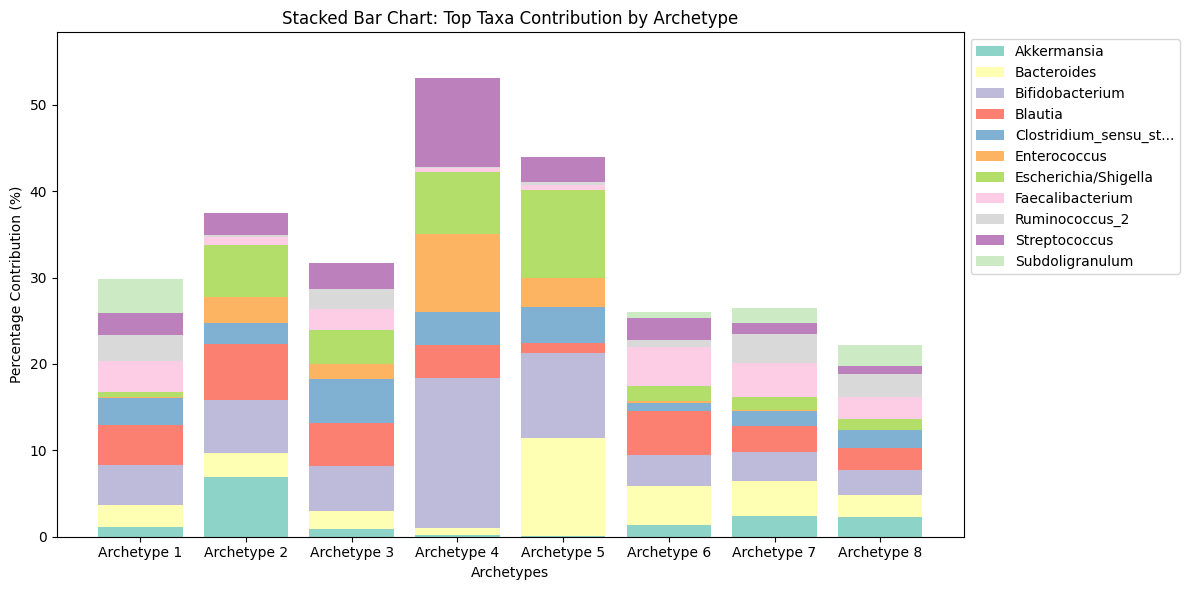

: 

In [ ]:
composition_analyzer.plot_stacked_bar_chart(aa_archetypes=aa_archetypes, sort_by_contribution=False, feature_names=otu.columns, top_taxa_archetypes=top_taxa_archs, figsize=(12, 6))

## PCoA Comparison

In [36]:
data_loader = CompendiumDataLoader()
otu_file = r"datasets\compendium\normalized\compendium_Norm_QC-region3k_AdultsOnly.csv"
projects_file = r"datasets/compendium/projects.csv"
tags_file = r"datasets/compendium/tags.tsv"
meta_file = r"datasets/compendium/sample_metadata.tsv"
otu, projects, tags, meta = data_loader.load_all(otu_file=otu_file, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)


In [3]:
filter_cols = ["region"]
legend_type = "discrete"  # "continuous" or "discrete"
metadata = extract_metadata(otu.index, tags, meta, projects, filter_cols, verbose=False)

pcoa_visualizer = PCoAVisualizer()
pcoa_coords, pcoa_results = pcoa_visualizer.create_pcoa_from_otu(
    otu_data=otu,
    distance_metric="jensenshannon",
    n_dimensions=5,
    apply_log_transform=True,
    clean_data=True,
    verbose=False
)


c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\pcoa.py:105: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  x_explained = pcoa_results.proportion_explained[int(x_pc[-1])-1]
c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\pcoa.py:106: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y_explained = pcoa_results.proportion_explained[int(y_pc[-1])-1]


(<Figure size 1800x600 with 3 Axes>,
 array([<Axes: title={'center': 'PC1 vs PC2'}, xlabel='PC1 (12.74% variance explained)', ylabel='PC2 (6.01% variance explained)'>,
        <Axes: title={'center': 'PC2 vs PC3'}, xlabel='PC2 (6.01% variance explained)', ylabel='PC3 (4.91% variance explained)'>,
        <Axes: title={'center': 'PC1 vs PC3'}, xlabel='PC1 (12.74% variance explained)', ylabel='PC3 (4.91% variance explained)'>],
       dtype=object))

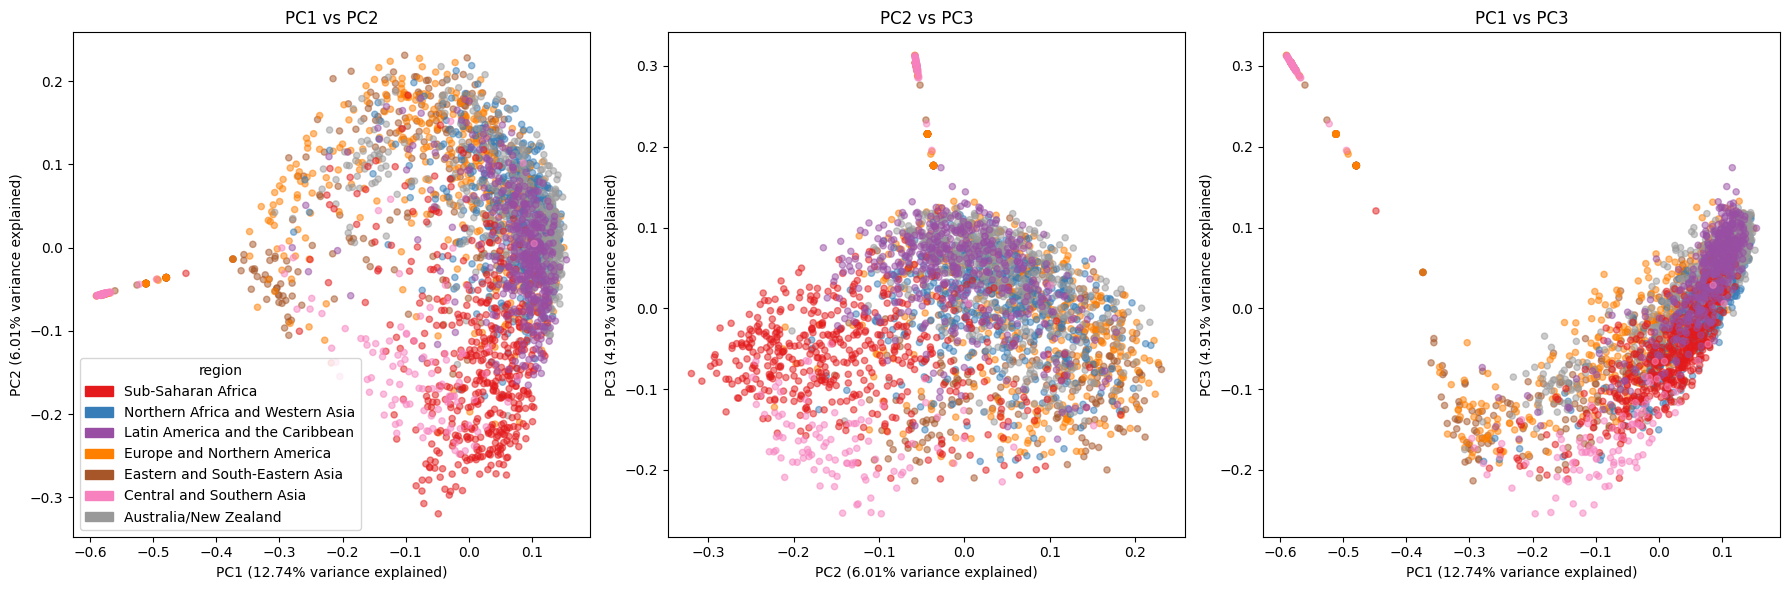

In [4]:
pcoa_visualizer.plot_pcoa(
    pcoa_coordinates=pcoa_coords, 
    pcoa_results=pcoa_results,
    metadata=metadata, 
    filter_col=filter_cols[0],
    legend_type=legend_type,
    pc_combinations=[('PC1', 'PC2'), ('PC2', 'PC3'), ('PC1', 'PC3')], 
    cmap_name="Set1", 
    s=20
)

In [38]:
# Plot PC1 and PC2 with Plotly for interactivity
import plotly.express as px

# Create new metadata with region, project, sample_type, condition, notes
filter_cols = ["region", "project", "sample_type", "condition", "notes"]
new_metadata = extract_metadata(otu.index, tags, meta, projects, filter_cols, verbose=False)

# Get intersection of indices
common_indices = pcoa_coords.index.intersection(new_metadata.index)
filtered_pcoa_coords = pcoa_coords.loc[common_indices]
filtered_metadata = new_metadata.loc[common_indices]

fig = px.scatter(
    filtered_pcoa_coords,
    x='PC1',
    y='PC2',
    color=filtered_metadata['condition'],
    hover_data={
        'project': filtered_metadata['project'],
        'sample_type': filtered_metadata['sample_type'],
        'condition': filtered_metadata['condition'],
        'notes': filtered_metadata['notes']
    },
    title='PCoA Plot (PC1 vs PC2) Colored by Region',
    labels={'PC1': 'Principal Component 1', 'PC2': 'Principal Component 2'},
    color_discrete_sequence=px.colors.qualitative.Set1
)
fig.show()
# Fucked Projects
# PRJNA399246
# PRJNA396815
# PRJNA558158
# PRJNA606262

## Num Archs Analysis

In [37]:
data_loader = CompendiumDataLoader()
projects_file = r"datasets/compendium/projects.csv"
tags_file = r"datasets/compendium/tags.tsv"
meta_file = r"datasets\tsv\dog_sam.tsv"
_, projects, tags, meta = data_loader.load_all(otu_file=None, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)


In [38]:
loader = ArchetypalResultLoader()
resultsDir = r"results\Dog\norm_lifestyle200"
nIdx_archs = [3,4,5,6,7,8,9,10,11,12]
k_results = loader.load_multiple_results(k_values=nIdx_archs, directory=resultsDir)

Evaluating K: 100%|██████████| 10/10 [00:00<00:00, 251.29it/s]


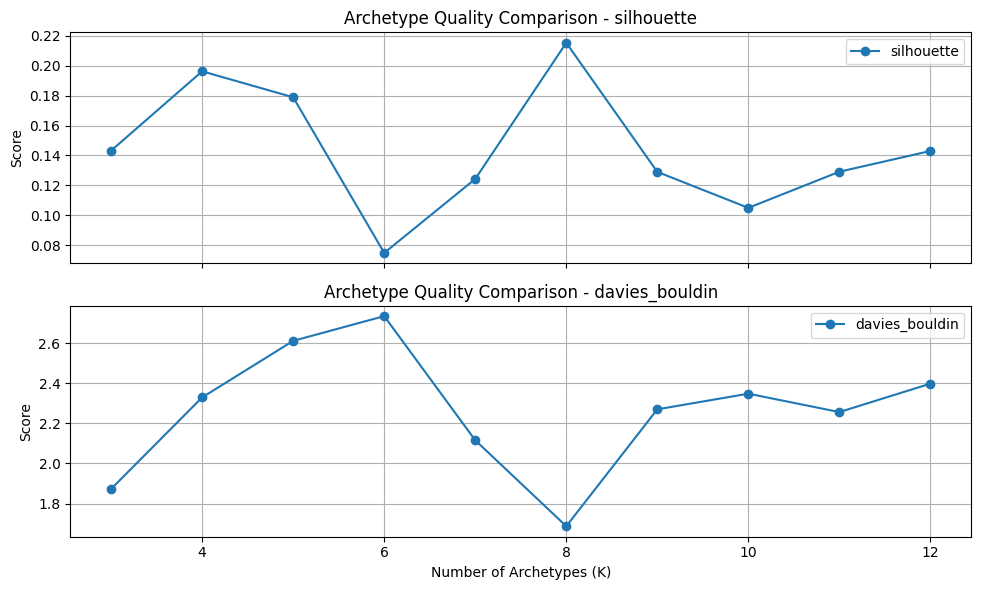

In [41]:
filter_cols = ["Lifestyle"]
discretize = False
metadata = extract_metadata(k_results[nIdx_archs[0]]["index"], tags, meta, projects, filter_cols, verbose=False)

analysis_metrics = AnalysisMetrics()
analysis_results = analysis_metrics.compare_archetype_quality(
    results_dict=k_results,
    metadata=metadata,
    metadata_column=filter_cols[0], 
    discretize=False, 
    buckets=None, 
    metrics=["silhouette", "davies_bouldin"]#, 'final_loss']
)
analysis_metrics.plot_comparison(comparison_df=analysis_results, figsize=(10, 6))

## Stacked Bar 

In [83]:
compendium_loader = CompendiumDataLoader() # HadzaDataLoader()
projects_file = r"datasets/compendium/projects.csv"
tags_file = r"datasets/compendium/tags.tsv"
meta_file = r"datasets\tsv\dog_sam.tsv"
_, projects, tags, meta = compendium_loader.load_all(otu_file=None, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)

filepath = r"results\Dog\norm_lifestyle200\otu_AA_K8_1.0_None_jensenshannon.json"
loader = ArchetypalResultLoader()
otu_aa, aa_labels, aa_archetypes, info = loader.load_parsed_result(filepath)


<Axes: ylabel='Similarity degree'>

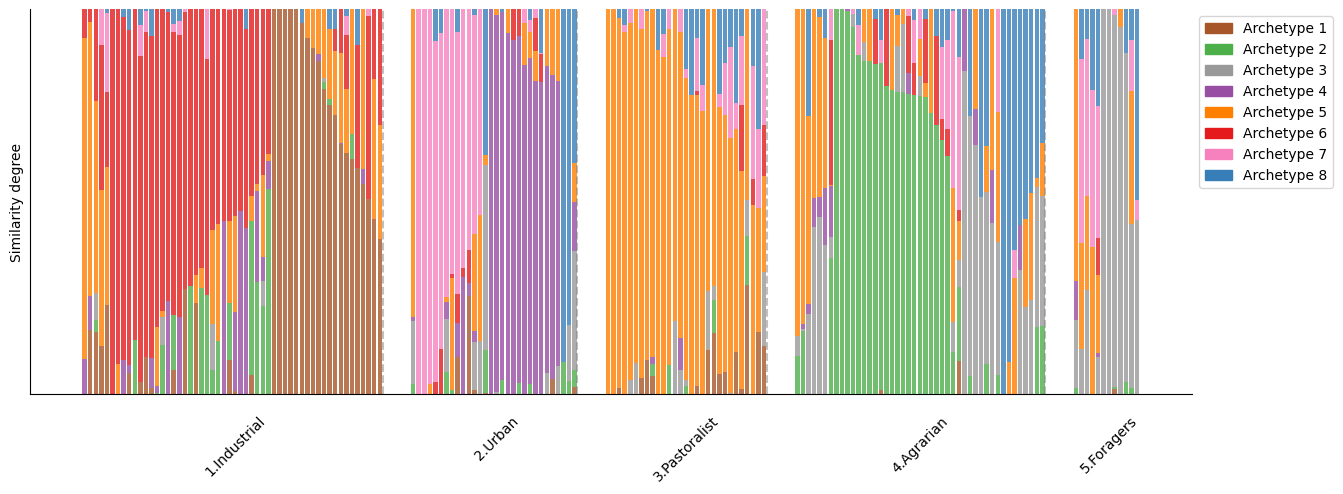

In [84]:
stacked_bar_plotter = StackedBarPlotter()
filter_cols = ["Lifestyle"]
metadata = extract_metadata(otu_aa.index, tags, meta, projects, extract_cols=filter_cols, verbose=False)
stacked_bar_plotter.plot_metadata_stacked_bars(
    similarity_degree=otu_aa, 
    metadata=metadata,
    perms=info.get('perms', None),
    metadata_column=filter_cols[0],
    discretize=False,
    buckets=None,
    cmap_name="Set1",
    vertex_colors={"Archetype 1": 6/9, "Archetype 2": 2/9, "Archetype 3": 8/9, "Archetype 4": 3/9, "Archetype 5": 4/9, "Archetype 6": 0/9, "Archetype 7": 7/9, "Archetype 8": 1/9}
)
# Dog200: {"Archetype 1": 6/20, "Archetype 2": 0/20, "Archetype 3": 4/20, "Archetype 4": 12/20, "Archetype 5": 8/20, "Archetype 6": 18/20, "Archetype 7": 16/20}
# Sample Metadata: {"Archetype 1": 6/20, "Archetype 2": 0/20, "Archetype 3": 4/20, "Archetype 4": 12/20, "Archetype 5": 8/20, "Archetype 6": 18/20, "Archetype 7": 16/20}
# Compendium 3k: {"Archetype 1": 10/20, "Archetype 2": 2/20, "Archetype 3": 0/20, "Archetype 4": 18/20, "Archetype 5": 6/20, "Archetype 6": 13/20}

Project columns: []
Sample columns: ['age_months']
Tag columns: []


<Axes: xlabel='Observations', ylabel='Similarity degree'>

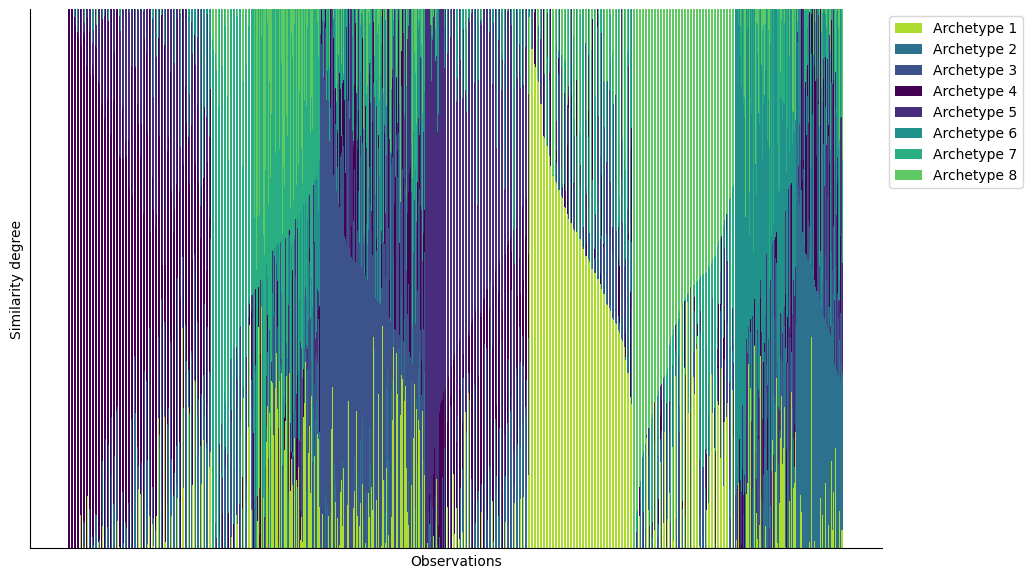

In [35]:
stacked_bar_plotter = StackedBarPlotter()
buckets = [(0,6), (6,12), (12,24), (24,36), (36,48), (48,60), (60, np.inf)]
filter_cols = ["age_months"]
metadata = extract_metadata(otu_aa.index, None, meta, None, extract_cols=filter_cols, verbose=True)
stacked_bar_plotter.plot_metadata_stacked_bars(
    similarity_degree=otu_aa, 
    metadata=metadata,
    perms=info.get('perms', None),
    metadata_column=None,
    figsize=(11,7),
    cmap_name="viridis",
    vertex_colors={"Archetype 4": 0/8, "Archetype 5":1/8 , "Archetype 3": 2/8, "Archetype 2": 3/8, "Archetype 6": 4/8, "Archetype 7": 5/8, "Archetype 8": 6/8, "Archetype 1": 7/8}
)

## Data Normalization

In [68]:
data_loader = HadzaDataLoader()
otu_file = r"datasets\tsv\hadza_otu_formatted.tsv"
projects_file = None #r"datasets/compendium/projects.csv"
tags_file = None #r"datasets/compendium/tags.tsv"
meta_file = r"datasets\tsv\hadza_meta_formatted.tsv" # r"datasets/compendium/sample_metadata.tsv"
otu, meta, _ = data_loader.load_all(otu_file=otu_file, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)
# otu, projects, tags, meta = data_loader.load_all(otu_file=otu_file, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)

c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\data\loaders.py:31: DtypeWarning:

Columns (3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,22,24,25,26,27,76,77,78,79,80,81,82,83,86,87,88,89,90,91,92,95,97,98,100,101,102,103,105,112,113,114,116,118,120,123,134,135,136,137,138,139,140,141,142,143,146,147,148,149,150,154,155,156,159,161,162,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,194,197,198) have mixed types. Specify dtype option on import or set low_memory=False.



In [ ]:
filter_cols = ["location", "age_binned", "age_months"]
metadata = extract_metadata(otu.index, tags, meta, projects, filter_cols, verbose=True)

# Value counts for age_binned
print("Total samples:", len(metadata))
max_age_bin = metadata["age_binned"].value_counts().index[0]
age_bin4_8 = metadata[metadata["age_binned"] == max_age_bin]

age_bin4_8["location"].value_counts()

Project columns: []
Sample columns: ['location', 'age_binned', 'age_months']
Tag columns: []
Total samples: 18593


location
Sweden              769
Finland             636
Malawi              542
Colorado            408
Germany             232
Washington          184
Bangladesh          133
Georgia             105
Peru                 77
India                50
South Africa         22
Brazil               14
Tanzania (Hadza)     11
Name: count, dtype: int64

In [86]:
test_meta = pd.read_csv("sampleID.csv")

In [96]:
locs = test_meta["Geography"].unique()
ind_status = {
    "NA/EU": {"USA", "Canada", "UK", "Austria", "Netherlands", "Germany", "France", "Italy", "Spain", "Sweden", "Denmark", "Finland", "Norway", "Belgium", "Switzerland", "Luxembourg" },
    "East Asia": {"China", "Japan", "South Korea", "Taiwan", "Hong Kong", "Mongolia" },
    "South Asia": {"India", "Pakistan", "Bangladesh", "Sri Lanka", "Nepal", "Vietnam", "Thailand", "Malaysia", "Indonesia", "Philippines", "Singapore"},
    "Africa": {"South Africa", "Nigeria", "Kenya", "Ghana", "Madagascar", "Tanzania", "Uganda", "Ethiopia", "Cameroon", "Zimbabwe", "Zambia", "Rwanda", "Senegal", "Ivory Coast", "Burkina Faso", "Mali", "Niger", "Chad", "Sudan", "Somalia", "Libya", "Algeria", "Morocco" },
    "Latin America": {"Mexico", "Brazil", "Argentina", "Colombia", "Peru", "Chile", "Venezuela", "Ecuador", "Bolivia", "Paraguay", "Uruguay", "Cuba", "Haiti", "Dominican Republic", "Guatemala", "Honduras", "El Salvador", "Nicaragua", "Costa Rica", "Panama" },
    "Middle East": {"Turkey", "Iran", "Iraq", "Saudi Arabia", "United Arab Emirates",},
    "Oceania": {"Australia", "New Zealand", "Fiji", "Papua New Guinea", "Samoa", "Tonga" },
    "Unknown": {"Unknown", "Other", "N/A", "Not Reported"}
}
def map_geography(geo):
    for region, countries in ind_status.items():
        if geo in countries:
            return region
    return "Other"

test_meta["Big_Geography"] = test_meta["Geography"].apply(map_geography)
test_meta[test_meta["Disease"]=="Healthy"]["Big_Geography"].value_counts()

Big_Geography
NA/EU            1641
East Asia        1134
Oceania           193
Africa            139
South Asia        125
Latin America      36
Name: count, dtype: int64

In [35]:
# Extract metadata for condition, and count thenumber of people that are "healthy"
filter_cols = ["condition", "subjects", "region"]
metadata = extract_metadata(otu.index, tags, meta, projects, filter_cols, verbose=True)
# Filter to condition healthy
healthy_samples = metadata[metadata["condition"] == "healthy"]
print(f"Number of healthy samples: {len(healthy_samples)} out of {len(metadata)} total samples.")

from archetypal_analysis.config import DatasetConfig
adults_subjects = DatasetConfig.SUBJECTS_NO_CONDITION_ADULTS
# Filter to adults subjects
adults_healthy = metadata[(metadata["condition"] == "healthy") & (metadata["subjects"].isin(adults_subjects))]
print(f"Number of healthy adult samples: {len(adults_healthy)} out of {len(metadata)} total samples.")

# Print value counts for subjects
print(adults_healthy["region"].value_counts())



Project columns: ['condition', 'subjects']
Sample columns: ['region']
Tag columns: []
Number of healthy samples: 54491 out of 168464 total samples.
Number of healthy adult samples: 28285 out of 168464 total samples.
region
Europe and Northern America         17652
unknown                              7896
Eastern and South-Eastern Asia       1113
Sub-Saharan Africa                   1015
Latin America and the Caribbean       443
Australia/New Zealand                 153
Central and Southern Asia               5
Northern Africa and Western Asia        4
Oceania                                 4
Name: count, dtype: int64


In [27]:
from archetypal_analysis.config import DatasetConfig
adults_subjects = DatasetConfig.SUBJECTS_NO_CONDITION_ADULTS
control = {"condition": ["healthy"], "subjects": adults_subjects} 
# normalize = {"sample_type": ['cervicovaginal swab', 'appendiceal tissue', 'stool', 'ileal mucosal sample', 'fixed tissue samples', 'esophageal biopsy', 'tumor samples']}
normalize = {"region": None}
ignore = ["unknown", "Oceania", "Northern Africa and Western Asia", "Central and Southern Asia"]
tol = 1
data_normalizer = DataNormalizer()
sample_type_norm, norm_meta = data_normalizer.normalize_data(
    control=control,
    normalize=normalize,
    otu=otu,
    meta=meta, projects=projects, tags=tags,
    continuous=False,
    ignore=ignore,
    tol=tol,
    verbose=True
)

Project columns: ['condition', 'subjects']
Sample columns: ['region']
Tag columns: []
Number of samples before control filtering: 168464
Number of samples after control filtering: 28285
Value unknown ignored
Value Northern Africa and Western Asia ignored
Value Central and Southern Asia ignored
Value Oceania ignored
Minimum counts: 153 for value Australia/New Zealand
Ignored 4 values
                                 region
Eastern and South-Eastern Asia      306
Europe and Northern America         306
Latin America and the Caribbean     306
Australia/New Zealand               153
Sub-Saharan Africa                  306

Normalized Data shape:  (1377, 3)


In [ ]:
qc = QualityController()
sample_type_norm = qc.quality_control(
    otu=sample_type_norm, 
    save_dir=r"datasets\tsv\normalized",
    save_name=r"compendium_Norm_QC-regionnk_Adults_HealthyOnly.csv",
    verbose=True,
    min_taxa_level=3, 
    min_nonzero_samples=0.01,
    min_counts=5000,
)

Starting quality control on OTU table...
Initial OTU table shape: (170, 264)
Removed 0 columns with unknown Class
Removed 0 columns with non-zero values in less than 1.0% samples (1 samples)
Removed 0 samples with total counts less than 5000
Filtered OTU table shape: (170, 264)
Saved filtered data to dog_otu_normalized_Lifestyle.csv


In [65]:
dog_sam = pd.read_table(r"datasets\tsv\dog_sam.tsv", index_col=0)
print(dog_sam["Lifestyle"].value_counts())

Lifestyle
1.Industrial     107
4.Agrarian        66
2.Urban           39
3.Pastoralist     30
5.Foragers        19
Name: count, dtype: int64


In [53]:
dog_otu = pd.read_csv(r"datasets\tsv\normalized\dog_otu_normalized_Lifestyle.csv", index_col=0)

In [60]:
otu_file = r"datasets\tsv\dog_otu.tsv"
tax_file = r"datasets\tsv\dog_tax.tsv"
meta_file = r"datasets\tsv\dog_sam.tsv"

otu = pd.read_table(otu_file, index_col=0)
tax = pd.read_table(tax_file, index_col=0)
meta = pd.read_table(meta_file, index_col=0)

In [61]:
group = "Genus" # Change this to "Kingdom", "Phylum", "Class", "Order", "Family", "Genus",to group by that taxonomic level

# No of uniques => {Kingdom: 1, Phylum: 15, Class: 25, Order: 44, Family: 77, Genus: 305}

# For each column, create a string of form "Phylum.Class.Order.Family.Genus"
def create_taxa_string(row):
    return ".".join([str(x) for x in row if x != "NA"])

# change the column names to the taxonomic strings
tax_strings = tax.apply(create_taxa_string, axis=1)
# change the column names of the otu table to the taxonomic strings
otu.columns = tax_strings



# Save the grouped otu table to a tsv file
out_path = f"datasets/tsv/dog_otu_formatted.tsv"
otu.to_csv(out_path, sep="\t")
